# Steering what a network learns: the numbers and plots

**AI 4200, Week 9.1 (Tuesday, Oct 27): CNNs and inductive bias.** This notebook reproduces the numbers and plots on the lecture board *Steering what a network learns*. On Thursday the MLP passed the test set but failed the shift test, and shift augmentation was the fix. Today the same invariance is built into the architecture instead, with a residual CNN. The notebook has two kinds of cells:

- **Hand-computed slides** (locality, sliding a filter, pooling, weight counts): small NumPy computations on Thursday's 7. They run in seconds.
- **Experiments**: a residual pre-norm MLP and a residual CNN trained on the same 8,000 digits, then tested on shifted, rescaled and shuffled digits.

**What you need.** Internet access (the MNIST digits come from the npm package [`mnist` 1.1.0](https://www.npmjs.com/package/mnist): 10,000 digits, split 8,000 train / 2,000 test as on Thursday, with Thursday's 7 as test digit 0), PyTorch, NumPy and matplotlib. A GPU is optional: the notebook uses CUDA when it is available (on Colab: *Runtime → Change runtime type → T4 GPU*) and the CPU otherwise.

**Runtime.** The experiments train about 30 networks for 3,000–3,750 steps each. That takes several hours on a 2-core CPU and much less on a GPU. Every finished run is saved to `results_04/results.json`, so rerunning the notebook skips it and an interrupted run resumes where it stopped. On Colab, set `SAVE_TO_DRIVE = True` to keep that file in Google Drive. `QUICK = True` is a smoke test: 30 steps per run and one seed. Its trained numbers are meaningless; it only checks that every cell runs.

**Where the numbers come from.** The code is a cleaned-up version of the scripts that made the slides, with the same seeds, data, step counts and hyperparameters. Hand-computed numbers match the slides exactly. Trained numbers can differ by a few tenths of a point with a different PyTorch build, CPU or GPU. A few slides have no code behind them (illustrations, Thursday's results, published numbers); they are flagged where they occur.

## Setup

### Flags, device and the results cache

`device` is the GPU if there is one, else the CPU. Models are moved to it once; data stays on the CPU and each batch is moved inside the training and evaluation loops.

In [1]:
QUICK = False               # True: smoke test, 30 steps per run and 1 seed (numbers meaningless)
SAVE_TO_DRIVE = False       # Colab only: keep the results cache in Google Drive
RUN_PADDING_CHECK = False   # True: also train the plain CNNs behind the "Borders matter too" card

import io
import json
import os
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Markdown, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cpu":
    torch.set_num_threads(2)   # the slide runs used 2 CPU threads; the same count gives the same CPU numbers

RESULTS_DIR = "results_04_quick" if QUICK else "results_04"
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = os.path.join("/content/drive/MyDrive", RESULTS_DIR)
os.makedirs(RESULTS_DIR, exist_ok=True)
RESULTS_FILE = os.path.join(RESULTS_DIR, "results.json")

RESULTS = {}
if os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE) as f:
        RESULTS = json.load(f)
print(len(RESULTS), "finished runs in", RESULTS_FILE)


def save_result(key, value):
    """Store one finished run and rewrite the cache file."""
    RESULTS[key] = value
    # write to a temporary file first, so a crash mid-write cannot corrupt the cache
    with open(RESULTS_FILE + ".tmp", "w") as f:
        json.dump(RESULTS, f)
    os.replace(RESULTS_FILE + ".tmp", RESULTS_FILE)


def steps(n):
    """The real step count, or 30 in QUICK mode."""
    return 30 if QUICK else n


def seeds(n):
    """Seeds 0..n-1, or only seed 0 in QUICK mode."""
    return range(1) if QUICK else range(n)

device: cuda
0 finished runs in results_04/results.json


### Data

The npm package stores one JSON file per digit class; its `"data"` field holds that class's pixel values in 0..1, 784 per image. They are concatenated in class order 0, 1, …, 9. A fixed permutation (`RandomState(0)`) makes the split: Thursday's 7 (dataset index 7190) is test digit 0, followed by 1,999 more test digits; the next 8,000 are the training set.

In [2]:
MNIST_URL = "https://registry.npmjs.org/mnist/-/mnist-1.1.0.tgz"
with urllib.request.urlopen(MNIST_URL) as response:
    archive = tarfile.open(fileobj=io.BytesIO(response.read()), mode="r:gz")

images, labels = [], []
for digit in range(10):
    pixels = json.load(archive.extractfile(f"package/src/digits/{digit}.json"))["data"]
    digit_images = np.array(pixels, dtype=np.float32).reshape(-1, 1, 28, 28)
    images.append(digit_images)
    labels.append(np.full(len(digit_images), digit, dtype=np.int64))
X_all = np.concatenate(images)
y_all = np.concatenate(labels)

SEVEN = 7190                       # Thursday's example 7
rng = np.random.RandomState(0)
order = rng.permutation(len(X_all))
order = order[order != SEVEN]
TEST = np.concatenate([[SEVEN], order[:1999]])
TRAIN = order[1999:1999 + 8000]

X_train, y_train = torch.tensor(X_all[TRAIN]), torch.tensor(y_all[TRAIN])
X_test, y_test = torch.tensor(X_all[TEST]), torch.tensor(y_all[TEST])
print("train", tuple(X_train.shape), "| test", tuple(X_test.shape), "| test digit 0 is a", int(y_test[0]))

train (8000, 1, 28, 28) | test (2000, 1, 28, 28) | test digit 0 is a 7


### Image helpers

Every image operation used by the slides and the experiments. They work on a batch of shape `(n, 1, 28, 28)`; `shift` also works on a single 2-D NumPy image.

- `shift`: move right by `dx` and down by `dy` pixels, zero fill. Used for the shift test.
- `random_shift`: a random shift in [−3, 3] on each axis for each image (pad 3, crop at a random offset). This is the augmentation.
- `rescale` / `random_rescale`: scale about the centre (bilinear, zero fill); the random version draws a scale in [0.8, 1.2] per image.
- `permute_pixels` and `thursday_perm`: Thursday's fixed pixel shuffle (Park–Miller generator, seed 1234, then a Fisher–Yates shuffle).

In [3]:
def shift(images, dx=0, dy=0):
    """Move images right by dx and down by dy pixels (negative: left / up), filling with zeros."""
    height, width = images.shape[-2], images.shape[-1]
    out = images * 0                     # zeros with the same shape and type (NumPy or torch)
    src_rows = slice(max(0, -dy), height - max(0, dy))
    dst_rows = slice(max(0, dy), height - max(0, -dy))
    src_cols = slice(max(0, -dx), width - max(0, dx))
    dst_cols = slice(max(0, dx), width - max(0, -dx))
    out[..., dst_rows, dst_cols] = images[..., src_rows, src_cols]
    return out


def random_shift(images, max_shift=3):
    """Shift each image by its own random offset in [-max_shift, max_shift] on both axes."""
    padded = F.pad(images, (max_shift, max_shift, max_shift, max_shift))
    n = len(images)
    offset_x = torch.randint(0, 2 * max_shift + 1, (n,))
    offset_y = torch.randint(0, 2 * max_shift + 1, (n,))
    out = torch.empty_like(images)
    for i in range(n):
        out[i] = padded[i, :, offset_y[i]:offset_y[i] + 28, offset_x[i]:offset_x[i] + 28]
    return out


def rescale(images, scale):
    """Scale images about their centre by `scale` (a number, or one value per image); bilinear, zero fill."""
    theta = torch.zeros(len(images), 2, 3)
    theta[:, 0, 0] = 1 / scale           # the grid maps output to input coordinates, hence 1 / scale
    theta[:, 1, 1] = 1 / scale
    grid = F.affine_grid(theta, images.shape, align_corners=False)
    return F.grid_sample(images, grid, mode="bilinear", padding_mode="zeros", align_corners=False)


def random_rescale(images, low=0.8, high=1.2):
    """Rescale each image by its own random factor in [low, high]."""
    scales = torch.empty(len(images)).uniform_(low, high)
    return rescale(images, scales)


def permute_pixels(images, perm):
    """Apply the same fixed pixel shuffle to every image."""
    return images.reshape(len(images), 784)[:, perm].reshape(-1, 1, 28, 28)


def thursday_perm(seed=1234):
    """Thursday's fixed shuffle of the 784 pixels: Park-Miller random numbers, Fisher-Yates shuffle."""
    perm = list(range(784))
    for j in range(783, 0, -1):
        seed = (seed * 16807) % 2147483647
        m = int(np.floor(seed / 2147483647 * (j + 1)))
        perm[j], perm[m] = perm[m], perm[j]
    return torch.tensor(perm)


PERM = thursday_perm()

### Models

- `ResMLP`: Thursday's residual MLP with pre-norm blocks, h ← h + Linear(ReLU(Linear(LayerNorm(h)))): 784 → 256, two blocks, 10 outputs.
- `ResCNN`: a 5 × 5 conv stem with 32 channels → max pool (28 → 14) → residual block → max pool (14 → 7) → two more blocks → GroupNorm → ReLU → head. Each block is x + Conv3×3(ReLU(GroupNorm(Conv3×3(ReLU(GroupNorm(x)))))).
  - The **GAP head** averages each channel over all positions, so it throws position away.
  - The **dense head** flattens the 32 × 7 × 7 map into a Linear layer, so every position has its own weights.
  - `num_blocks` < 3 cuts the network short for *Depth makes it global*; the second pool comes before the second block.

`make_model` sets the seed before building, so a seed always gives the same initial weights.

In [4]:
class MLPBlock(nn.Module):
    """Pre-norm residual block: h + Linear(ReLU(Linear(LayerNorm(h))))."""

    def __init__(self, width):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.fc1 = nn.Linear(width, width)
        self.fc2 = nn.Linear(width, width)

    def forward(self, h):
        return h + self.fc2(F.relu(self.fc1(self.norm(h))))


class ResMLP(nn.Module):
    """Residual pre-norm MLP: 784 -> 256, two blocks, LayerNorm, ReLU, 10 logits."""

    def __init__(self, width=256, num_blocks=2):
        super().__init__()
        self.inp = nn.Linear(784, width)
        self.blocks = nn.ModuleList([MLPBlock(width) for _ in range(num_blocks)])
        self.norm = nn.LayerNorm(width)
        self.out = nn.Linear(width, 10)

    def forward(self, x):
        h = self.inp(x.flatten(1))
        for block in self.blocks:
            h = block(h)
        return self.out(F.relu(self.norm(h)))


class ConvBlock(nn.Module):
    """Pre-norm residual conv block: x + Conv(ReLU(GroupNorm(Conv(ReLU(GroupNorm(x))))))."""

    def __init__(self, channels):
        super().__init__()
        self.norm1 = nn.GroupNorm(1, channels)
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(1, channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1)

    def forward(self, x):
        h = self.conv1(F.relu(self.norm1(x)))
        h = self.conv2(F.relu(self.norm2(h)))
        return x + h


class ResCNN(nn.Module):
    """Residual CNN: 5x5 stem, max pool, residual blocks (pool after the first), GroupNorm, GAP or dense head."""

    def __init__(self, head="gap", num_blocks=3, channels=32):
        super().__init__()
        self.stem = nn.Conv2d(1, channels, 5, padding=2)
        self.blocks = nn.ModuleList([ConvBlock(channels) for _ in range(num_blocks)])
        self.norm = nn.GroupNorm(1, channels)
        self.head = head
        self.out = nn.Linear(channels * 49 if head == "dense" else channels, 10)

    def forward(self, x):
        x = F.max_pool2d(self.stem(x), 2)        # 28 x 28 -> 14 x 14
        for i, block in enumerate(self.blocks):
            if i == 1:
                x = F.max_pool2d(x, 2)           # 14 x 14 -> 7 x 7
            x = block(x)
        x = F.relu(self.norm(x))
        if self.head == "dense":
            x = x.flatten(1)                     # every position keeps its own weights
        else:
            x = x.mean((2, 3))                   # global average pool: position is thrown away
        return self.out(x)


def make_model(kind, seed, num_blocks=3):
    """Build 'mlp', 'cnn_gap' or 'cnn_dense' with a fixed seed and move it to the device."""
    torch.manual_seed(seed)
    if kind == "mlp":
        model = ResMLP()
    elif kind == "cnn_dense":
        model = ResCNN("dense", num_blocks)
    else:
        model = ResCNN("gap", num_blocks)
    return model.to(device)


def count_weights(model):
    """Number of trainable numbers (weights and biases)."""
    return sum(p.numel() for p in model.parameters())

### Training and evaluation

One `train` function serves every experiment: AdamW (lr 2e-3, weight decay 1e-4), a cosine learning-rate schedule, batches of 128, and a fresh shuffle of the training set each epoch (the last partial batch is dropped). `aug` picks the augmentation and `perm` shuffles the pixels. Each batch is augmented on the CPU and then moved to the device.

Two experiments log accuracy *during* training. They pass `after_step`, a function called after every step, and their own random `generator` for the batch order. That keeps one training loop, with exactly the random numbers the original runs drew.

`predict` evaluates in batches of 500 under `torch.no_grad()` and returns the predicted classes on the CPU; `accuracy` turns them into a percentage.

In [5]:
BATCH_SIZE = 128


def batch_indices(n, batch_size, generator):
    """Yield batches of shuffled indices forever, reshuffling when the next batch would run past the end."""
    order = torch.randperm(n, generator=generator)
    position = 0
    while True:
        if position + batch_size > n:
            order = torch.randperm(n, generator=generator)
            position = 0
        yield order[position:position + batch_size]
        position += batch_size


def augment(xb, aug=None, perm=None):
    """Apply the training-time augmentation and/or pixel shuffle to one batch (on the CPU)."""
    if aug == "shift":
        xb = random_shift(xb, 3)
    elif aug == "scale":
        xb = random_rescale(xb)
    if perm is not None:
        xb = permute_pixels(xb, perm)
    return xb


def train(model, X, y, num_steps, lr=2e-3, weight_decay=1e-4, aug=None, perm=None, seed=0,
          generator=None, after_step=None):
    """Train with AdamW and a cosine schedule for num_steps batches of 128."""
    torch.manual_seed(seed)                   # the augmentation draws come from torch's global generator
    if generator is None:
        generator = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_steps)
    batches = batch_indices(len(X), BATCH_SIZE, generator)
    for step in range(1, num_steps + 1):
        idx = next(batches)
        xb = augment(X[idx], aug, perm)
        yb = y[idx]
        xb, yb = xb.to(device), yb.to(device)
        model.train()
        y_hat = model(xb)                     # logits
        loss = F.cross_entropy(y_hat, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        if after_step is not None:
            after_step(step)
    model.eval()
    return model


@torch.no_grad()
def predict(model, X, perm=None):
    """Predicted class for every image, computed in batches of 500 and returned on the CPU."""
    model.eval()
    if perm is not None:
        X = permute_pixels(X, perm)
    predictions = []
    for start in range(0, len(X), 500):
        xb = X[start:start + 500].to(device)
        predictions.append(model(xb).argmax(1).cpu())
    return torch.cat(predictions)


def accuracy(model, X, y, perm=None):
    """Percentage of images classified correctly."""
    return (predict(model, X, perm) == y).float().mean().item() * 100

### Plotting helpers and Thursday's 7

The hand-computed slides draw Thursday's 7 with 10 grey levels (0, 1/9, …, 1), so the image is rounded the same way here. With that rounding every hand-computed number below matches the slides exactly. `conv_valid` is the convolution as the slides write it, ŷ[i, j] = Σₐ Σ_b W[a, b] · X[s·i + a, s·j + b] for stride s, with no padding.

In [6]:
BLUE, ORANGE, INK, GREY = "#2557D6", "#C2510F", "#16181D", "#8E94A0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E8EB", "lines.linewidth": 2})


def show_image(ax, image, title="", cmap="Greys", vmin=None, vmax=None):
    """Draw one image without ticks or grid."""
    ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


def conv_valid(image, W, stride=1):
    """Slide the k x k filter W over the image with the given stride, no padding; returns y_hat."""
    k = W.shape[0]
    size = (image.shape[0] - k) // stride + 1
    y_hat = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            window = image[stride * i:stride * i + k, stride * j:stride * j + k]
            y_hat[i, j] = (W * window).sum()
    return y_hat


# Thursday's 7, rounded to the 10 grey levels the slides use
seven = np.round(X_all[SEVEN, 0] * 9).astype(np.float64) / 9

# the hand-made top-edge filter: two rows of -1, a row of 0, two rows of +1
W_TOP = np.array([[-1, -1, -1, -1, -1],
                  [-1, -1, -1, -1, -1],
                  [0, 0, 0, 0, 0],
                  [1, 1, 1, 1, 1],
                  [1, 1, 1, 1, 1]], dtype=float)

---
## Fast to generalize, slow to memorize

*Slides 1–3 (title, quiz announcement, recap) have no code; the model-space map on* Learning isn't enough *is an illustration.*

The MLP is trained twice for 60 epochs (3,750 steps), once on true labels and once with 20% of the training labels flipped to a wrong class. Accuracy is logged about once per epoch (every 63 steps, plus steps 5, 10, 20 and 40). What to notice: with flipped labels, test accuracy first rises almost as fast as with clean labels, while the flipped labels are memorized only later, and test accuracy falls as they are.

To flip labels, a generator seeded with 100 + seed picks 20% of the training digits and adds a random 1–9 to each label, mod 10. The same generator then sets the batch order.

true labels: 90.1% after 1.01 epochs, 96.3% at the end (train 100.0%)
20% flipped: peak 92.9% at epoch 8 with 7.4% of flipped labels memorized; end 83.6% with 100.0% memorized


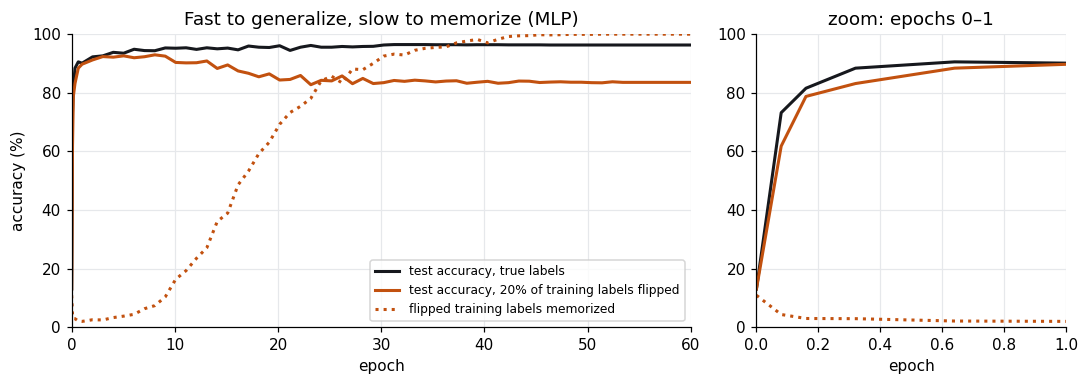

In [7]:
def flip_labels(y, fraction, generator):
    """Give a random `fraction` of the labels a wrong class; returns the new labels and which ones were flipped."""
    flipped = torch.rand(len(y), generator=generator) < fraction
    y_noisy = y.clone()
    wrong_by = torch.randint(1, 10, (int(flipped.sum()),), generator=generator)   # 1..9, never 0
    y_noisy[flipped] = (y_noisy[flipped] + wrong_by) % 10
    return y_noisy, flipped


def run_trajectory(kind, noise, seed=0):
    """Train on labels with a `noise` fraction flipped, logging accuracy about once per epoch."""
    key = f"traj|{kind}|{noise}|{seed}"
    if key in RESULTS:
        return RESULTS[key]
    model = make_model(kind, seed)
    generator = torch.Generator().manual_seed(100 + seed)
    y_noisy, flipped = flip_labels(y_train, noise, generator)
    X_test_shift6 = shift(X_test, 6)
    num_steps = steps(3750)
    log = []

    def record(step):
        train_pred = predict(model, X_train)
        entry = {"step": step,
                 "epoch": round(step * BATCH_SIZE / len(X_train), 2),
                 "train": (train_pred == y_noisy).float().mean().item() * 100,
                 "clean": accuracy(model, X_test, y_test),
                 "s6": accuracy(model, X_test_shift6, y_test)}
        if noise > 0:
            entry["noisy_fit"] = (train_pred[flipped] == y_noisy[flipped]).float().mean().item() * 100
        log.append(entry)

    def after_step(step):
        if step % 63 == 0 or step in (5, 10, 20, 40) or step == num_steps:
            record(step)

    record(0)
    train(model, X_train, y_noisy, num_steps, seed=seed, generator=generator, after_step=after_step)
    save_result(key, log)
    return log


def closest_epoch(log, epoch):
    """The log entry nearest to the given epoch."""
    return min(log, key=lambda entry: abs(entry["epoch"] - epoch))


def plot_trajectory(lines, zoom_to, title):
    """Accuracy against epoch (0-60) with a zoom panel on the first `zoom_to` epochs."""
    fig, (ax, ax_zoom) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [2, 1]})
    for log, field, color, style, label in lines:
        epochs = [entry["epoch"] for entry in log]
        values = [entry[field] for entry in log]
        ax.plot(epochs, values, color=color, ls=style, label=label)
        ax_zoom.plot(epochs, values, color=color, ls=style, label=label)
    ax.set(xlim=(0, 60), ylim=(0, 100), xlabel="epoch", ylabel="accuracy (%)", title=title)
    ax_zoom.set(xlim=(0, zoom_to), ylim=(0, 100), xlabel="epoch", title=f"zoom: epochs 0–{zoom_to}")
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


mlp_clean = run_trajectory("mlp", 0.0)
mlp_noisy = run_trajectory("mlp", 0.2)

mlp_epoch1 = closest_epoch(mlp_clean, 1)
mlp_peak = max(mlp_noisy, key=lambda entry: entry["clean"])
print(f"true labels: {mlp_epoch1['clean']:.1f}% after {mlp_epoch1['epoch']} epochs, "
      f"{mlp_clean[-1]['clean']:.1f}% at the end (train {mlp_clean[-1]['train']:.1f}%)")
print(f"20% flipped: peak {mlp_peak['clean']:.1f}% at epoch {round(mlp_peak['epoch'])} "
      f"with {mlp_peak['noisy_fit']:.1f}% of flipped labels memorized; "
      f"end {mlp_noisy[-1]['clean']:.1f}% with {mlp_noisy[-1]['noisy_fit']:.1f}% memorized")
plot_trajectory([(mlp_clean, "clean", INK, "-", "test accuracy, true labels"),
                 (mlp_noisy, "clean", ORANGE, "-", "test accuracy, 20% of training labels flipped"),
                 (mlp_noisy, "noisy_fit", ORANGE, ":", "flipped training labels memorized")],
                1, "Fast to generalize, slow to memorize (MLP)")

---
## Invariances: changes that keep the label

*Data augmentation is expensive* (the slide before) shows Thursday's results (notebook 02), not computed here: the plain MLP at 95.6, 91.3, 71.8, 45.2, 26.0, 14.1, 8.2% for 0–6 px shifts, the augmented MLP at 95.9, 96.1, 95.4, 94.4, 91.7, 80.9, 60.3%, and the 1,715 versions per digit (1.0 × 10⁸ images).

Here: Thursday's 7 changed five ways that keep the label (shift, rotation, scale, thicker strokes), and a 6 from the dataset rotated 180°, which becomes a 9.

the 6 is dataset index 5997


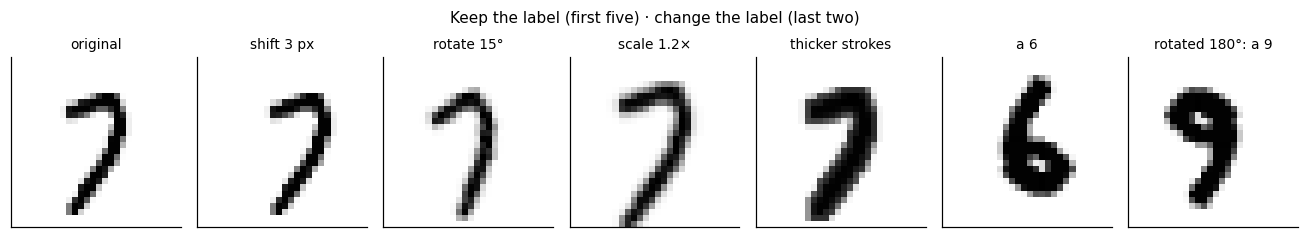

In [8]:
def rotate(images, degrees):
    """Rotate images about their centre (bilinear, zero fill)."""
    a = np.deg2rad(degrees)
    theta = torch.tensor([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0]], dtype=torch.float32)
    grid = F.affine_grid(theta.unsqueeze(0).repeat(len(images), 1, 1), images.shape, align_corners=False)
    return F.grid_sample(images, grid, align_corners=False)


def thicken(images):
    """Thicker strokes: mostly a 3 x 3 max filter, a little of the original."""
    return torch.clamp(F.max_pool2d(images, 3, 1, 1) * 0.85 + images * 0.15, 0, 1)


x7 = torch.tensor(X_all[SEVEN:SEVEN + 1])
six_index = int(np.where(y_all == 6)[0][3])
x6 = torch.tensor(X_all[six_index:six_index + 1])
print("the 6 is dataset index", six_index)

examples = [(x7, "original"), (shift(x7, 3), "shift 3 px"), (rotate(x7, 15), "rotate 15°"),
            (rescale(x7, 1.2), "scale 1.2×"), (thicken(x7), "thicker strokes"),
            (x6, "a 6"), (torch.flip(x6, [2, 3]), "rotated 180°: a 9")]
fig, axs = plt.subplots(1, 7, figsize=(12, 2.2))
for ax, (image, title) in zip(axs, examples):
    show_image(ax, image[0, 0], title)
plt.suptitle("Keep the label (first five) · change the label (last two)", fontsize=10)
plt.tight_layout()
plt.show()

---
## Assumption 1: locality

*Slides 7–8 (*Two paths to learning invariances*, *A CNN makes two assumptions*) have no code; their "where training is likely to land" contours are illustrations.*

Neurons compute ŷ = Σᵢ Wᵢ xᵢ (no bias) and h = ReLU(ŷ) on the 7, with **random, untrained** weights in [−1, 1] rounded to 19 levels. The slide steps from "every neuron sees every pixel" to less input per neuron:

1. Two neurons see all 784 pixels (slide: h = 5.0 and 4.7).
2. Neuron 1 sees only the top half, neuron 2 only the bottom half (slide: 1.9 and 1.0).
3. Four neurons, one per quarter.
4. 144 neurons, one per 5 × 5 window at stride 2, each with its own weights.

For steps 1–3 the slide's weights came from a search over seeds for weights whose outputs stay positive before and after the cut, so ReLU never just shows 0. The search below reproduces them.

seed 110
neuron 1: all input h = 5.0 | half the input h = 1.9
neuron 2: all input h = 4.7 | half the input h = 1.0
quarter (rows, cols) (0, 14, 0, 14) seed 505 h = 1.63
quarter (rows, cols) (0, 14, 14, 28) seed 506 h = 0.89
quarter (rows, cols) (14, 28, 0, 14) seed 508 h = 2.26
quarter (rows, cols) (14, 28, 14, 28) seed 515 h = 1.36
12 x 12 = 144 neurons with 25 weights each


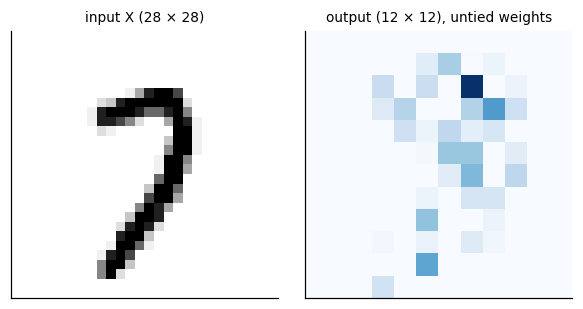

In [9]:
def random_weights(seed):
    """784 random weights in [-1, 1], rounded to 19 levels (multiples of 1/9), as a 28 x 28 array."""
    return np.round(np.random.RandomState(seed).uniform(-1, 1, (28, 28)) * 9) / 9


def region_mask(row0, row1, col0, col1):
    """1 inside the given rows and columns of a 28 x 28 image, 0 elsewhere."""
    mask = np.zeros((28, 28))
    mask[row0:row1, col0:col1] = 1
    return mask


# steps 1-2: two neurons, then each sees only half the image
halves = [region_mask(0, 14, 0, 28), region_mask(14, 28, 0, 28)]
for seed in range(5000):
    rng = np.random.RandomState(seed)
    W_halves = [np.round(rng.uniform(-1, 1, (28, 28)) * 9) / 9 for _ in range(2)]
    full_out = [(W * seven).sum() for W in W_halves]
    half_out = [(W * seven * mask).sum() for W, mask in zip(W_halves, halves)]
    good = all(1.5 < f < 6 and 1.0 < h < 5 and abs(f - h) > 0.8 for f, h in zip(full_out, half_out))
    if good:
        break
print("seed", seed)
for n in range(2):
    print(f"neuron {n + 1}: all input h = {max(0, full_out[n]):.1f} | half the input h = {max(0, half_out[n]):.1f}")

# step 3: one neuron per quarter, each with the first seed after 500 that gives an output in (0.6, 3)
quarters = [(0, 14, 0, 14), (0, 14, 14, 28), (14, 28, 0, 14), (14, 28, 14, 28)]
seed = 500
for quarter in quarters:
    while True:
        seed += 1
        out = (random_weights(seed) * seven * region_mask(*quarter)).sum()
        if 0.6 < out < 3:
            break
    print("quarter (rows, cols)", quarter, "seed", seed, f"h = {out:.2f}")

# step 4: 5 x 5 windows at stride 2, every window with its own random weights
num_windows = (28 - 5) // 2 + 1
rng = np.random.RandomState(2027)
untied = np.zeros((num_windows, num_windows))
for i in range(num_windows):
    for j in range(num_windows):
        W = np.round(rng.uniform(-1, 1, (5, 5)), 1)
        untied[i, j] = max(0.0, (W * seven[2 * i:2 * i + 5, 2 * j:2 * j + 5]).sum())
print(f"{num_windows} x {num_windows} = {num_windows ** 2} neurons with 25 weights each")

fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.8))
show_image(axs[0], seven, "input X (28 × 28)")
show_image(axs[1], untied, "output (12 × 12), untied weights", cmap="Blues")
plt.tight_layout()
plt.show()

The untied 12 × 12 output is noise, not a picture of the 7. The slide drew it from a different random generator, so the pattern differs in detail.

---
## Assumption 2: the same detector everywhere

One shared 5 × 5 filter used at every position is a convolution, ŷᵢⱼ = Σₐ Σ_b W_ab X_{i+a, j+b}. The slide counts the weights needed for one 24 × 24 map of units on a 28 × 28 input (slide: 4.5 × 10⁵, 1.4 × 10⁴, 25):

In [10]:
units = 24 * 24
print(f"fully connected : 784 x {units} = {784 * units:,}  (≈ {784 * units:.1e})")
print(f"local 5 x 5     : 25 x {units} = {25 * units:,}  (≈ {25 * units:.1e})")
print("local and shared: 25")

fully connected : 784 x 576 = 451,584  (≈ 4.5e+05)
local 5 x 5     : 25 x 576 = 14,400  (≈ 1.4e+04)
local and shared: 25


---
## Sliding the filter

The same 5 × 5 windows at stride 2 as the locality slide, but every neuron now uses the **same** W, the top-edge filter. The 12 × 12 output ReLU(ŷ) lights up along the top edges of the 7 (slide: strongest window 9.1).

feature map (12, 12) | strongest window 9.1


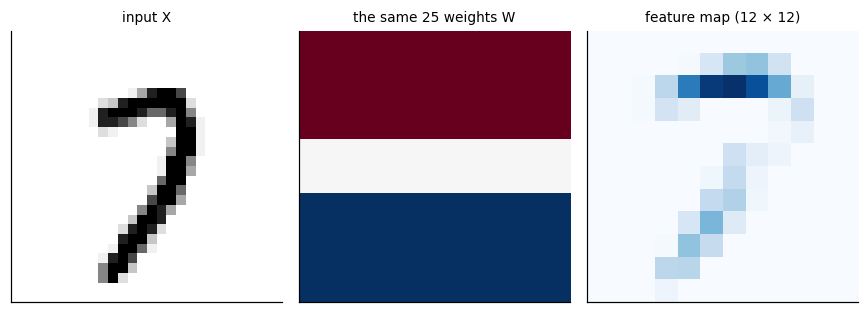

In [11]:
tied = np.maximum(conv_valid(seven, W_TOP, stride=2), 0)
print("feature map", tied.shape, "| strongest window", round(tied.max(), 1))

fig, axs = plt.subplots(1, 3, figsize=(8, 2.8))
show_image(axs[0], seven, "input X")
show_image(axs[1], W_TOP, "the same 25 weights W", cmap="RdBu", vmin=-1, vmax=1)
show_image(axs[2], tied, "feature map (12 × 12)", cmap="Blues")
plt.tight_layout()
plt.show()

---
## Shift in, shift out

W ∗ X for the 7 and for the 7 shifted 3 px right (the one Thursday's MLP read as a 3), stride 1, no padding, before ReLU. Shifting the input shifts the feature map by the same amount: W ∗ shift(X) = shift(W ∗ X), so the difference is 0 (slide: max |difference| = 0.0).

max |difference| = 0.0


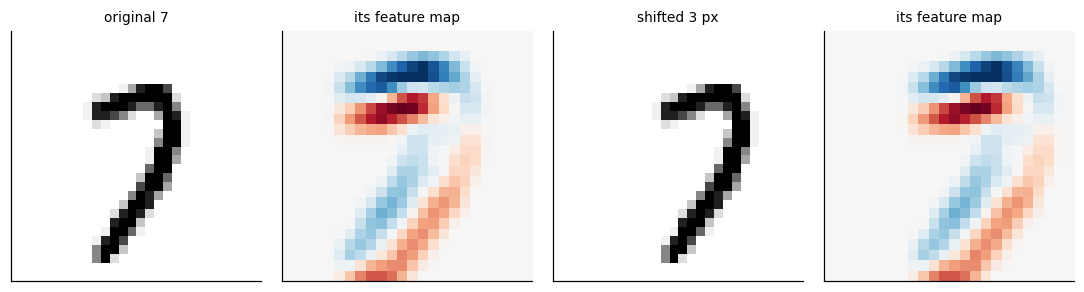

In [12]:
fmap = conv_valid(seven, W_TOP)
fmap_of_shifted = conv_valid(shift(seven, 3), W_TOP)
difference = fmap_of_shifted - shift(fmap, 3)
print("max |difference| =", round(np.abs(difference).max(), 1))

limit = np.abs(fmap).max()
fig, axs = plt.subplots(1, 4, figsize=(10, 2.6))
show_image(axs[0], seven, "original 7")
show_image(axs[1], fmap, "its feature map", cmap="RdBu", vmin=-limit, vmax=limit)
show_image(axs[2], shift(seven, 3), "shifted 3 px")
show_image(axs[3], fmap_of_shifted, "its feature map", cmap="RdBu", vmin=-limit, vmax=limit)
plt.tight_layout()
plt.show()

---
## Additional filters add additional channels

A second filter W₂ detects left edges (two columns of −1, a column of 0, two columns of +1). Each filter gives one 12 × 12 image (stride 2, ReLU); stacked, they form a 2 × 12 × 12 output with one channel per filter.

stacked: (2, 12, 12)


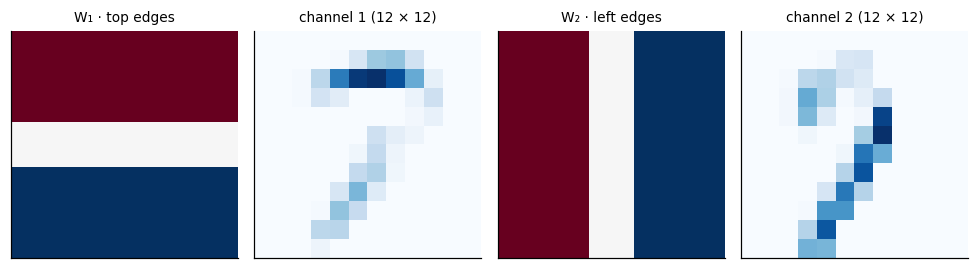

In [13]:
W_LEFT = W_TOP.T.copy()     # the top-edge filter turned on its side
channel1 = np.maximum(conv_valid(seven, W_TOP, stride=2), 0)
channel2 = np.maximum(conv_valid(seven, W_LEFT, stride=2), 0)
stacked = np.stack([channel1, channel2])
print("stacked:", stacked.shape)

fig, axs = plt.subplots(1, 4, figsize=(9, 2.5))
show_image(axs[0], W_TOP, "W₁ · top edges", cmap="RdBu", vmin=-1, vmax=1)
show_image(axs[1], channel1, "channel 1 (12 × 12)", cmap="Blues")
show_image(axs[2], W_LEFT, "W₂ · left edges", cmap="RdBu", vmin=-1, vmax=1)
show_image(axs[3], channel2, "channel 2 (12 × 12)", cmap="Blues")
plt.tight_layout()
plt.show()

---
## One Conv2d, 32 filters, 32 channels · How big is each output channel?

`nn.Conv2d(1, 32, 5, padding=2)` holds 32 filters of 1 × 5 × 5 (slide: 800 weights) and turns a 1 × 28 × 28 image into 32 × 28 × 28. The output size along one axis is ⌊(N + 2p − k) / s⌋ + 1; the slide works it on a row of 7 pixels (5, 7 and 4 outputs) and for our two convolutions (28 and 12).

In [14]:
def output_size(N, k, padding=0, stride=1):
    """Outputs along one axis for input size N, kernel k."""
    return (N + 2 * padding - k) // stride + 1


conv = nn.Conv2d(1, 32, 5, padding=2)
print("weight", tuple(conv.weight.shape), "=", conv.weight.numel(), "weights | output",
      tuple(conv(torch.zeros(1, 1, 28, 28)).shape))
print("N = 7, k = 3:", output_size(7, 3),
      "| padding 1:", output_size(7, 3, padding=1),
      "| padding 1, stride 2:", output_size(7, 3, padding=1, stride=2))
print("first conv:", output_size(28, 5, padding=2), "| two-filter slide:", output_size(28, 5, stride=2))

weight (32, 1, 5, 5) = 800 weights | output (1, 32, 28, 28)
N = 7, k = 3: 5 | padding 1: 7 | padding 1, stride 2: 4
first conv: 28 | two-filter slide: 12


---
## Filters look across all channels

A colour image has three channels. One 3 × 3 × 3 filter (+0.3 on R, 0 on G, −0.3 on B: "warm minus cool") sums all 27 products per position, so three channels in give **one** 15 × 15 channel out (stride 2, ReLU). On this CIFAR-10 cat it is bright on the orange wall and dark on the blue blanket. The image is downloaded from GitHub; the cell skips if that fails.

output (15, 15)


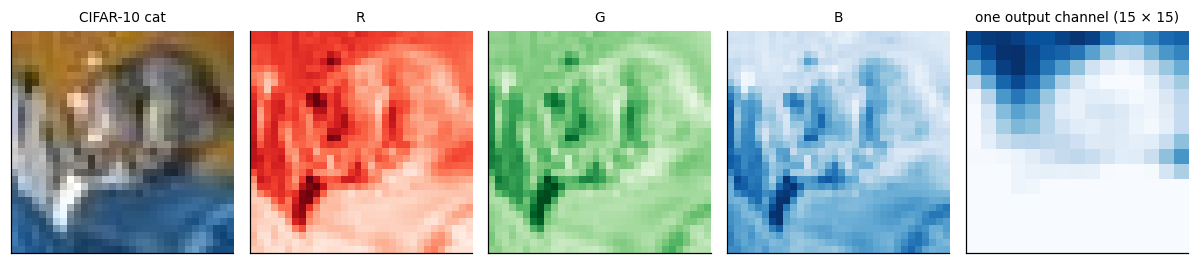

In [15]:
CAT_URL = "https://raw.githubusercontent.com/YoongiKim/CIFAR-10-images/master/test/cat/0000.jpg"
try:
    from PIL import Image
    with urllib.request.urlopen(CAT_URL, timeout=30) as response:
        cat = np.asarray(Image.open(io.BytesIO(response.read())).convert("RGB")).astype(float) / 255
except Exception as error:
    cat = None
    print("CIFAR image not available, skipping:", error)

if cat is not None:
    channel_weights = [0.3, 0.0, -0.3]                 # R, G, B
    box = np.ones((3, 3))
    y_hat = sum(w * conv_valid(cat[:, :, c], box, stride=2) for c, w in enumerate(channel_weights))
    sheet = np.maximum(y_hat, 0)
    print("output", sheet.shape)

    fig, axs = plt.subplots(1, 5, figsize=(11, 2.4))
    show_image(axs[0], cat, "CIFAR-10 cat")
    for c, (name, cmap) in enumerate([("R", "Reds"), ("G", "Greens"), ("B", "Blues")]):
        show_image(axs[c + 1], cat[:, :, c], name, cmap=cmap, vmin=0, vmax=1)
    show_image(axs[4], sheet, "one output channel (15 × 15)", cmap="Blues")
    plt.tight_layout()
    plt.show()

---
## Feature maps still have addresses

*Slide 17 (*Where we are in the network*) has no code.*

Equivariance is not invariance: the feature map of the shifted 7 is a moved copy, so many cells change value (slide: 207 of 576). Taking the maximum over larger and larger regions makes the result change less, and the maximum over the whole map does not change at all (slide: no pooling 114%, 2 × 2 90%, 4 × 4 66%, 6 × 6 45%, 12 × 12 17%, whole map 0%). The change is the L1 change of the region maxima as a share of the original.

cells that change: 207 of 576
 1 x 1  regions: change 114.3%
 2 x 2  regions: change 90.2%
 4 x 4  regions: change 65.9%
 6 x 6  regions: change 44.8%
12 x 12 regions: change 17.0%
24 x 24 regions: change 0.0%


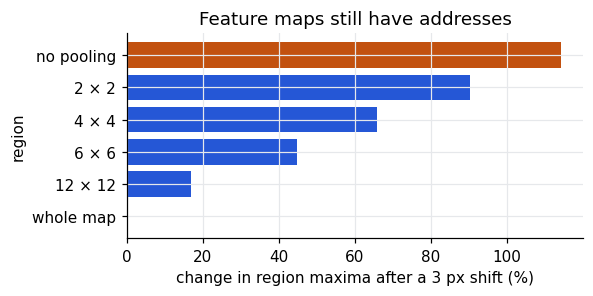

In [16]:
def region_max(fmap, size):
    """Maximum over each non-overlapping size x size region."""
    n = fmap.shape[0] // size
    return fmap.reshape(n, size, n, size).max(axis=(1, 3))


relu_map = np.maximum(conv_valid(seven, W_TOP), 0)                    # 24 x 24, stride 1
relu_map_shifted = np.maximum(conv_valid(shift(seven, 3), W_TOP), 0)
changed = (np.abs(relu_map - relu_map_shifted) > 0.05).sum()
print("cells that change:", changed, "of", relu_map.size)

region_sizes = [1, 2, 4, 6, 12, 24]
region_change = []
for size in region_sizes:
    before = region_max(relu_map, size)
    after = region_max(relu_map_shifted, size)
    region_change.append(100 * np.abs(before - after).sum() / before.sum())
    print(f"{size:2d} x {size:<2d} regions: change {region_change[-1]:.1f}%")

names = ["no pooling" if s == 1 else "whole map" if s == 24 else f"{s} × {s}" for s in region_sizes]
plt.figure(figsize=(5.5, 2.8))
plt.barh(names[::-1], region_change[::-1], color=[BLUE] * 5 + [ORANGE])
plt.xlabel("change in region maxima after a 3 px shift (%)")
plt.ylabel("region")
plt.title("Feature maps still have addresses")
plt.tight_layout()
plt.show()

---
## Max pooling keeps each window's winner

A 2 × 2, stride-2 max pool turns the 24 × 24 top-edge map (after ReLU) into 12 × 12: 576 values become 144. The slide ends on the strongest window (slide: 9.1, 9.1, 1.9, 1.7 → 9.1). Pooling alone does not make the 7 shift-invariant: after a 1 px shift only 6 of the 54 nonzero pooled values stay the same.

after a 1 px shift: 6 of 54 nonzero pooled values unchanged
strongest window: row 1 column 6 values [3.4, 4.1, 8.4, 9.1] -> 9.1


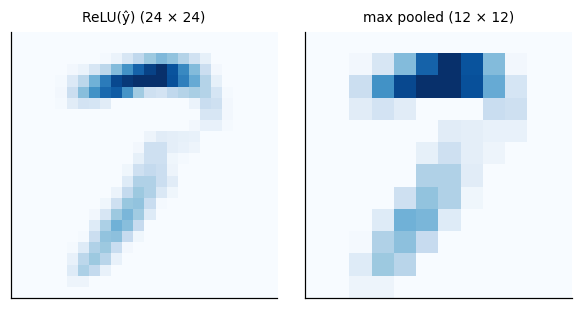

In [17]:
def max_pool_2x2(fmap):
    """2 x 2 max pooling with stride 2."""
    return region_max(fmap, 2)


pooled = max_pool_2x2(relu_map)
pooled_shift1 = max_pool_2x2(np.maximum(conv_valid(shift(seven, 1), W_TOP), 0))
nonzero = (pooled > 1e-9) | (pooled_shift1 > 1e-9)
unchanged = (np.abs(pooled_shift1 - pooled) < 1e-9) & nonzero
print("after a 1 px shift:", unchanged.sum(), "of", nonzero.sum(), "nonzero pooled values unchanged")

# the strongest window (the first one, reading row by row, if there is a tie)
best_i, best_j = 0, 0
for i in range(12):
    for j in range(12):
        if pooled[i, j] > pooled[best_i, best_j]:
            best_i, best_j = i, j
window = relu_map[2 * best_i:2 * best_i + 2, 2 * best_j:2 * best_j + 2]
print("strongest window: row", best_i, "column", best_j, "values", np.round(window.flatten(), 1).tolist(),
      "->", round(window.max(), 1))

fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.8))
show_image(axs[0], relu_map, "ReLU(ŷ) (24 × 24)", cmap="Blues")
show_image(axs[1], pooled, "max pooled (12 × 12)", cmap="Blues")
plt.tight_layout()
plt.show()

---
## From equivariant to invariant

**Global average pooling** reduces each channel to its mean. A shift that keeps the digit inside the image only moves the feature map, so the mean is identical for the original and the shifted 7.

In [18]:
print(f"GAP of ReLU(W * X), original 7:   {relu_map.mean():.3f}")
print(f"GAP of ReLU(W * X), shifted 3 px: {relu_map_shifted.mean():.3f}")

GAP of ReLU(W * X), original 7:   0.610
GAP of ReLU(W * X), shifted 3 px: 0.610


---
## The network shrinks where, keeps what

The shapes passed along the residual CNN, printed by running a blank image through its layers one at a time (the same steps as `ResCNN.forward`): 784, 196 and 49 positions per channel, then 1 after GAP.

In [19]:
model = make_model("cnn_gap", 0)
with torch.no_grad():
    x = torch.zeros(1, 1, 28, 28).to(device)
    print("input              ", tuple(x.shape))
    x = model.stem(x)
    print("stem conv          ", tuple(x.shape))
    x = F.max_pool2d(x, 2)
    print("max pool           ", tuple(x.shape))
    x = model.blocks[0](x)
    print("block 1            ", tuple(x.shape))
    x = F.max_pool2d(x, 2)
    print("max pool           ", tuple(x.shape))
    x = model.blocks[2](model.blocks[1](x))
    print("blocks 2 and 3     ", tuple(x.shape))
    x = F.relu(model.norm(x)).mean((2, 3), keepdim=True)
    print("norm, ReLU, GAP     ", tuple(x.shape))
    x = model.out(x.flatten(1))
    print("Linear (10 logits) ", tuple(x.shape))

input               (1, 1, 28, 28)
stem conv           (1, 32, 28, 28)
max pool            (1, 32, 14, 14)
block 1             (1, 32, 14, 14)
max pool            (1, 32, 7, 7)
blocks 2 and 3      (1, 32, 7, 7)
norm, ReLU, GAP      (1, 32, 1, 1)
Linear (10 logits)  (1, 10)


---
## The whole network (weight counts)

*Slides 22–23 (GroupNorm) explain with diagrams and have no code.*

Slide: 57,098 weights for the CNN with the GAP head, 8× fewer than the residual MLP's 468,234; 72,458 with the dense head (Linear 10 × 1,568); 18,624 per residual block and 9,248 per 3 × 3 conv (32 × 3 × 3 × 32 + 32).

In [20]:
for kind in ["mlp", "cnn_gap", "cnn_dense"]:
    print(f"{kind:10s} {count_weights(make_model(kind, 0)):,} weights")
print(f"one residual block: {count_weights(ConvBlock(32)):,} | one 3x3 conv 32 -> 32: "
      f"{count_weights(nn.Conv2d(32, 32, 3, padding=1)):,}")

mlp        468,234 weights
cnn_gap    57,098 weights
cnn_dense  72,458 weights
one residual block: 18,624 | one 3x3 conv 32 -> 32: 9,248


---
## The shift test, rerun

*Slides 25–26 are discussion and a prediction question (the 45% is Thursday's MLP at 3 px).*

Four models are trained on the 8,000 centred digits (3,750 steps, 3 seeds each) and tested on the 2,000 test digits shifted right by 0–6 px: the plain MLP, the MLP with random-shift augmentation (±3 px), and the CNN with a dense head and with a GAP head. What to notice: the GAP CNN, never shown a shifted digit, stays flat; the dense head, which keeps positions, falls off; augmentation helps the MLP only inside the range it was trained on.


main|mlp|None|None|0 test 96.1
main|mlp|None|None|1 test 96.5
main|mlp|None|None|2 test 96.2
main|mlp|shift|None|0 test 97.8
main|mlp|shift|None|1 test 98.0
main|mlp|shift|None|2 test 98.0
main|cnn_dense|None|None|0 test 98.5
main|cnn_dense|None|None|1 test 98.5
main|cnn_dense|None|None|2 test 98.8
main|cnn_gap|None|None|0 test 98.7
main|cnn_gap|None|None|1 test 98.7
main|cnn_gap|None|None|2 test 98.8
plain MLP            train 100.0  shift 0..6 px: [96.3, 94.1, 78.2, 49.9, 26.5, 14.7, 9.6] | the 7 shifted 0..6 px is read as [7, 7, 7, 0, 0, 0, 0]
MLP + augmentation   train  99.8  shift 0..6 px: [97.9, 98.0, 97.8, 97.1, 95.5, 90.2, 74.0] | the 7 shifted 0..6 px is read as [7, 7, 7, 7, 7, 7, 7]
CNN, dense head      train 100.0  shift 0..6 px: [98.6, 98.2, 96.8, 92.2, 76.1, 54.1, 37.3] | the 7 shifted 0..6 px is read as [7, 7, 7, 7, 7, 7, 7]
CNN, GAP head        train 100.0  shift 0..6 px: [98.7, 98.6, 98.6, 98.5, 98.4, 98.3, 97.9] | the 7 shifted 0..6 px is read as [7, 7, 7, 7, 7, 7, 7]


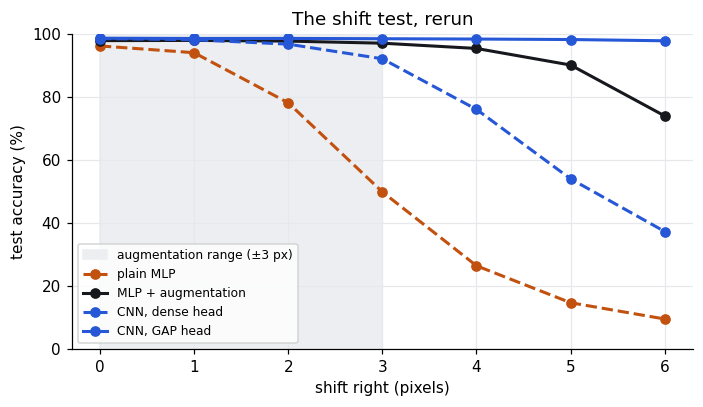

In [21]:
SCALES = [0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]
ONE_PIXEL_MOVES = [(1, 0), (-1, 0), (0, 1), (0, -1)]     # right, left, down, up


def run_main(kind, aug=None, shuffle_pixels=False, seed=0):
    """Train one model on all 8,000 digits for 3,750 steps and run every test on it."""
    key = f"main|{kind}|{aug}|{'perm' if shuffle_pixels else None}|{seed}"
    if key in RESULTS:
        return RESULTS[key]
    perm = PERM if shuffle_pixels else None
    model = make_model(kind, seed)
    train(model, X_train, y_train, steps(3750), aug=aug, perm=perm, seed=seed)
    result = {"params": count_weights(model),
              "train": accuracy(model, X_train, y_train, perm),
              "clean": accuracy(model, X_test, y_test, perm)}
    if not shuffle_pixels:
        result["shift"] = [accuracy(model, shift(X_test, d), y_test) for d in range(7)]
        result["scale"] = [accuracy(model, rescale(X_test, s), y_test) for s in SCALES]
        unshifted_pred = predict(model, X_test)
        result["flip1"] = [(predict(model, shift(X_test, dx, dy)) != unshifted_pred).float().mean().item() * 100
                           for dx, dy in ONE_PIXEL_MOVES]
        result["seven"] = [int(predict(model, shift(X_test[:1], d))[0]) for d in range(7)]
    if seed == 0:
        torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"main_{kind}_{aug}_{shuffle_pixels}.pt"))
    save_result(key, result)
    print(key, "test", round(result["clean"], 1))
    return result


def mean_of(runs, field):
    """Mean over seeds of a number or of a list of numbers."""
    return np.mean([run[field] for run in runs], axis=0)


CONFIGS = {"plain MLP": ("mlp", None), "MLP + augmentation": ("mlp", "shift"),
           "CNN, dense head": ("cnn_dense", None), "CNN, GAP head": ("cnn_gap", None)}
main_runs = {}
for name, (kind, aug) in CONFIGS.items():
    main_runs[name] = [run_main(kind, aug, seed=s) for s in seeds(3)]

shift_curve = {}
for name, runs in main_runs.items():
    shift_curve[name] = mean_of(runs, "shift")
    print(f"{name:20s} train {mean_of(runs, 'train'):5.1f}  shift 0..6 px:", np.round(shift_curve[name], 1).tolist(),
          "| the 7 shifted 0..6 px is read as", runs[0]["seven"])

styles = {"plain MLP": (ORANGE, "--"), "MLP + augmentation": (INK, "-"),
          "CNN, dense head": (BLUE, "--"), "CNN, GAP head": (BLUE, "-")}
plt.figure(figsize=(6.5, 3.8))
plt.axvspan(0, 3, color="#ECEEF1", zorder=0, label="augmentation range (±3 px)")
for name, (color, style) in styles.items():
    plt.plot(range(7), shift_curve[name], color=color, ls=style, marker="o", label=name)
plt.ylim(0, 100)
plt.xlabel("shift right (pixels)")
plt.ylabel("test accuracy (%)")
plt.title("The shift test, rerun")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Bias is worth data

Accuracy on test digits shifted 3 px against the number of training batches seen: every model sees batches of 128 from the same 8,000 digits, so "batches" measures how much data each one needs. Scored every 10 batches up to 600 and every 63 after that; one seed. What to notice: augmentation gets to 80% first, but the CNN overtakes it and reaches 95% about 6× sooner; the plain MLP never gets there.

Slide: batches to 95%: CNN 220, MLP + augmentation 1,323, plain MLP never (best 54.4%). Batches to 80%: MLP + augmentation 60, CNN 140; the CNN passes at about 138 batches (86%), interpolated between evaluations.

batches to 80%: MLP + aug 60 | CNN 120
crossover: 120 batches (82%)
batches to 95%: CNN 252 | MLP + aug 1260 | plain MLP None (best 53.3%)


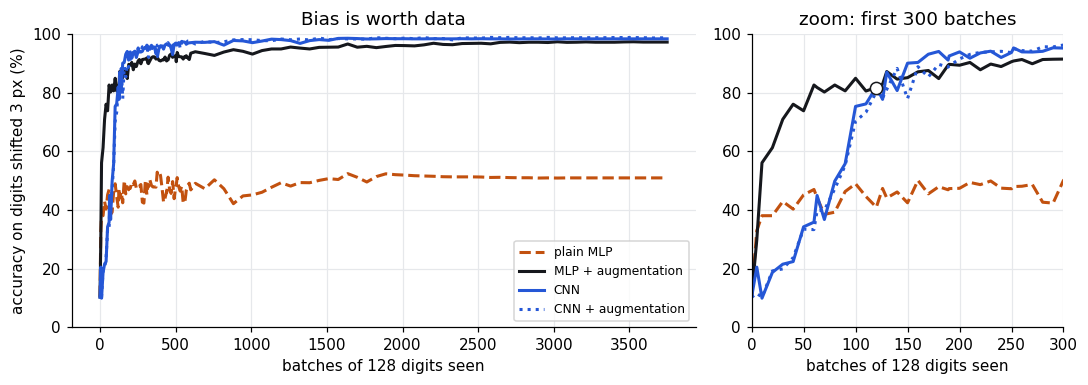

In [22]:
def run_batches_curve(kind, aug, seed=0):
    """Train with true labels and log accuracy on 3 px-shifted test digits as training goes."""
    key = f"dense|{kind}|{aug}|{seed}"
    if key in RESULTS:
        return RESULTS[key]
    model = make_model(kind, seed)
    generator = torch.Generator().manual_seed(100 + seed)
    flip_labels(y_train, 0.0, generator)      # flips nothing, but draws the same random numbers as
                                              # run_trajectory, so both runs see the same batch order
    X_test_shift3 = shift(X_test, 3)
    num_steps = steps(3750)
    log = []

    def record(step):
        log.append({"step": step, "s3": accuracy(model, X_test_shift3, y_test)})

    def after_step(step):
        if (step <= 600 and step % 10 == 0) or step % 63 == 0 or step == 5 or step == num_steps:
            record(step)

    record(0)
    train(model, X_train, y_train, num_steps, aug=aug, seed=seed, generator=generator, after_step=after_step)
    save_result(key, log)
    return log


def first_step(log, threshold):
    """First logged step with accuracy at or above threshold, or None."""
    for entry in log:
        if entry["s3"] >= threshold:
            return entry["step"]
    return None


curves = {"plain MLP": run_batches_curve("mlp", None),
          "MLP + augmentation": run_batches_curve("mlp", "shift"),
          "CNN": run_batches_curve("cnn_gap", None),
          "CNN + augmentation": run_batches_curve("cnn_gap", "shift")}

# where the CNN overtakes the augmented MLP, interpolated linearly between two evaluations
aug_log, cnn_log = curves["MLP + augmentation"][1:], curves["CNN"][1:]   # both logged at the same steps
crossover = None
for k in range(1, len(aug_log)):
    a0, a1 = aug_log[k - 1]["s3"], aug_log[k]["s3"]
    c0, c1 = cnn_log[k - 1]["s3"], cnn_log[k]["s3"]
    if c0 < a0 and c1 >= a1:
        t = (a0 - c0) / ((a0 - c0) + (c1 - a1))
        s0, s1 = aug_log[k - 1]["step"], aug_log[k]["step"]
        crossover = (s0 + t * (s1 - s0), a0 + t * (a1 - a0))
        break

to80_aug, to80_cnn = first_step(curves["MLP + augmentation"], 80), first_step(curves["CNN"], 80)
to95_aug, to95_cnn = first_step(curves["MLP + augmentation"], 95), first_step(curves["CNN"], 95)
mlp_best = max(entry["s3"] for entry in curves["plain MLP"])
print("batches to 80%: MLP + aug", to80_aug, "| CNN", to80_cnn)
print("crossover:", "none" if crossover is None else f"{crossover[0]:.0f} batches ({crossover[1]:.0f}%)")
print("batches to 95%: CNN", to95_cnn, "| MLP + aug", to95_aug, "| plain MLP", first_step(curves["plain MLP"], 95),
      f"(best {mlp_best:.1f}%)")

styles = {"plain MLP": (ORANGE, "--"), "MLP + augmentation": (INK, "-"),
          "CNN": (BLUE, "-"), "CNN + augmentation": (BLUE, ":")}
fig, (ax, ax_zoom) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [2, 1]})
for name, (color, style) in styles.items():
    batches = [entry["step"] for entry in curves[name]]
    values = [entry["s3"] for entry in curves[name]]
    ax.plot(batches, values, color=color, ls=style, label=name)
    ax_zoom.plot(batches, values, color=color, ls=style, label=name)
if crossover is not None:
    ax_zoom.plot([crossover[0]], [crossover[1]], "o", mfc="white", mec=INK, ms=8)
ax.set(ylim=(0, 100), xlabel="batches of 128 digits seen", ylabel="accuracy on digits shifted 3 px (%)",
       title="Bias is worth data")
ax_zoom.set(xlim=(0, 300), ylim=(0, 100), xlabel="batches of 128 digits seen", title="zoom: first 300 batches")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## What each model learned

Eight of the 32 first-layer 5 × 5 filters of the GAP CNN (seed 0 of the shift-test runs), each above its response on the 7 (zero padding 2, bias left out). The eight are chosen by ranking filters by the size of their mean-subtracted weights and skipping any that correlates above 0.6 with one already chosen. The four MLP units on the left of the slide are Thursday's weights and are not recomputed here.

chosen filters: [6, 19, 23, 3, 31, 14, 4, 1]


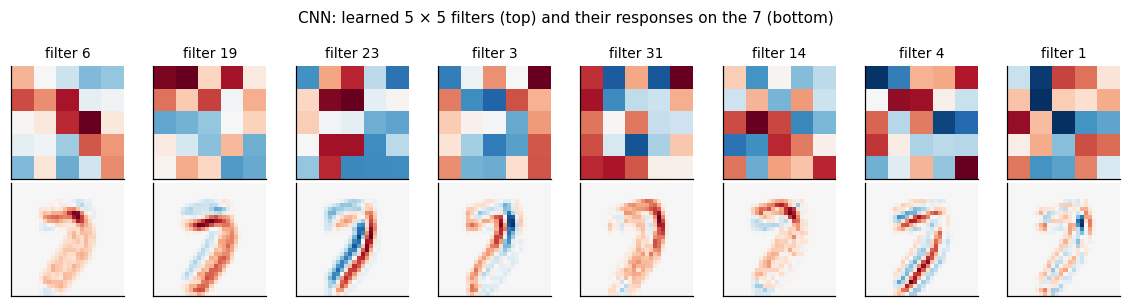

In [23]:
state = torch.load(os.path.join(RESULTS_DIR, "main_cnn_gap_None_False.pt"), map_location="cpu")
filters = state["stem.weight"][:, 0].numpy().reshape(32, 25)
centred = filters - filters.mean(axis=1, keepdims=True)

chosen = []
for i in np.argsort(-np.linalg.norm(centred, axis=1)):          # largest first
    correlations = [abs(np.dot(centred[i], centred[j])) / (np.linalg.norm(centred[i]) * np.linalg.norm(centred[j]))
                    for j in chosen]
    if all(c < 0.6 for c in correlations):
        chosen.append(int(i))
    if len(chosen) == 8:
        break
print("chosen filters:", chosen)

seven_padded = np.pad(seven, 2)
fig, axs = plt.subplots(2, 8, figsize=(10.5, 2.8))
for column, i in enumerate(chosen):
    W = filters[i].reshape(5, 5) / np.abs(filters[i]).max()     # scaled to [-1, 1] for display
    response = conv_valid(seven_padded, W)
    limit = np.abs(response).max()
    show_image(axs[0, column], W, f"filter {i}", cmap="RdBu", vmin=-1, vmax=1)
    show_image(axs[1, column], response, "", cmap="RdBu", vmin=-limit, vmax=limit)
plt.suptitle("CNN: learned 5 × 5 filters (top) and their responses on the 7 (bottom)", fontsize=10)
plt.tight_layout()
plt.show()

---
## The CNN takes the same road

The label-noise experiment from *Fast to generalize, slow to memorize*, repeated with the GAP CNN and scored on test digits shifted **6 px**. Slide: with true labels, 95.0% by epoch 8 and 97.9% at epoch 60. With 20% flipped, a peak of 97.0% at epoch 24 with 2.4% of flipped labels memorized, then 85.8% at epoch 60 with 38.9% memorized (the MLP memorized 100%).

true labels: 95.0% by epoch 8, 97.6% at epoch 60.0
20% flipped: peak 97.0% at epoch 24 with 3.1% memorized; end 85.1% with 33.7% memorized


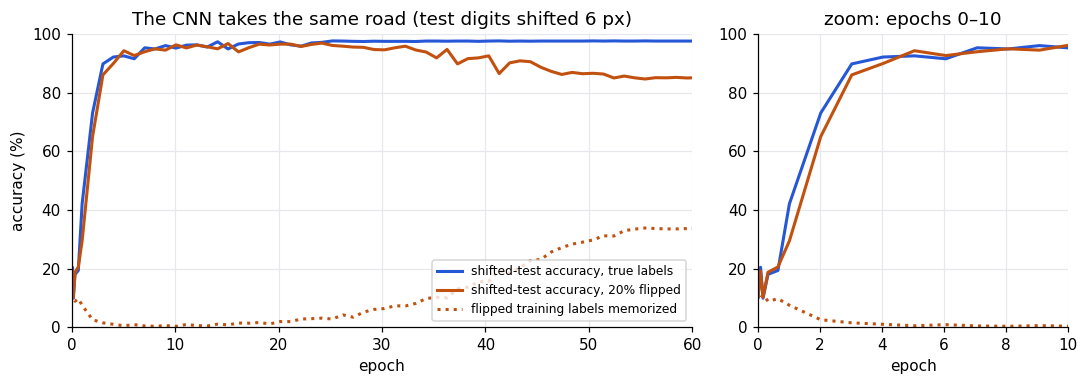

In [24]:
cnn_clean = run_trajectory("cnn_gap", 0.0)
cnn_noisy = run_trajectory("cnn_gap", 0.2)

cnn_epoch8 = closest_epoch(cnn_clean, 8)
cnn_peak = max(cnn_noisy, key=lambda entry: entry["s6"])
print(f"true labels: {cnn_epoch8['s6']:.1f}% by epoch {round(cnn_epoch8['epoch'])}, "
      f"{cnn_clean[-1]['s6']:.1f}% at epoch {cnn_clean[-1]['epoch']}")
print(f"20% flipped: peak {cnn_peak['s6']:.1f}% at epoch {round(cnn_peak['epoch'])} "
      f"with {cnn_peak['noisy_fit']:.1f}% memorized; "
      f"end {cnn_noisy[-1]['s6']:.1f}% with {cnn_noisy[-1]['noisy_fit']:.1f}% memorized")
plot_trajectory([(cnn_clean, "s6", BLUE, "-", "shifted-test accuracy, true labels"),
                 (cnn_noisy, "s6", ORANGE, "-", "shifted-test accuracy, 20% flipped"),
                 (cnn_noisy, "noisy_fit", ORANGE, ":", "flipped training labels memorized")],
                10, "The CNN takes the same road (test digits shifted 6 px)")

---
## Can a local model learn a global pattern? · When the assumption is wrong

Thursday's fixed pixel shuffle destroys locality: neighbouring pixels are no longer neighbours. Thursday's MLP barely noticed (95.6% → 94.7%, Thursday's numbers). Here the GAP CNN is trained from scratch on shuffled images (3 seeds). Slide: 98.7% → 91.7% (range 91.4–92.0%), with 100% of the shuffled training digits fitted: worse than with real images, but far above chance (10%).

main|cnn_gap|None|perm|0 test 91.9
main|cnn_gap|None|perm|1 test 91.6
main|cnn_gap|None|perm|2 test 92.0
CNN on normal digits 98.7% | on shuffled digits 91.8% (range 91.6–92.0) | shuffled train 100.0%


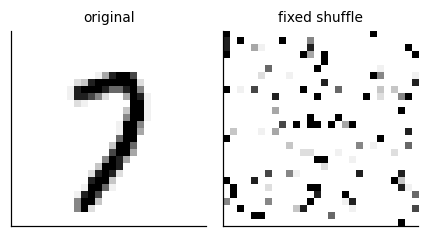

In [25]:
shuffled_runs = [run_main("cnn_gap", shuffle_pixels=True, seed=s) for s in seeds(3)]
normal_runs = main_runs["CNN, GAP head"]
shuffled_test = [run["clean"] for run in shuffled_runs]
print(f"CNN on normal digits {mean_of(normal_runs, 'clean'):.1f}% | on shuffled digits {np.mean(shuffled_test):.1f}% "
      f"(range {min(shuffled_test):.1f}–{max(shuffled_test):.1f}) | shuffled train {mean_of(shuffled_runs, 'train'):.1f}%")

fig, axs = plt.subplots(1, 2, figsize=(4, 2.2))
show_image(axs[0], seven, "original")
show_image(axs[1], seven.reshape(784)[PERM.numpy()].reshape(28, 28), "fixed shuffle")
plt.tight_layout()
plt.show()

---
## Local layers, global reach · Depth makes it global

Each layer sees a small window of the layer below, so the **receptive field** (the input region one unit can see) grows with depth. Each k × k layer adds (k − 1) × step pixels, where the step doubles after every pool. Slide: 5 → 14 → 32 → 48 pixels across (the slide hand-entered these; the loop below computes them).

Then the CNN is cut short: 0, 1 or 2 residual blocks instead of 3, trained on normal and on shuffled digits (one seed). With fewer than 2 blocks the second pool is absent and GAP averages a 14 × 14 map. The 3-block column reuses seed 0 of the main runs. Slide:


In [26]:
# (name, kernel size, stride) for every layer of ResCNN, in order
layers = [("stem 5x5", 5, 1), ("max pool", 2, 2),
          ("block 1 conv", 3, 1), ("block 1 conv", 3, 1), ("max pool", 2, 2),
          ("block 2 conv", 3, 1), ("block 2 conv", 3, 1),
          ("block 3 conv", 3, 1), ("block 3 conv", 3, 1)]
field, step = 1, 1
field_after = []
for name, k, stride in layers:
    field += (k - 1) * step       # a k x k window reaches (k - 1) more units of the layer below
    step *= stride                # after a pool, neighbouring units are `step` pixels apart
    field_after.append(field)
    print(f"after {name:13s} receptive field {field:2d} px")

after stem 5x5      receptive field  5 px
after max pool      receptive field  6 px
after block 1 conv  receptive field 10 px
after block 1 conv  receptive field 14 px
after max pool      receptive field 16 px
after block 2 conv  receptive field 24 px
after block 2 conv  receptive field 32 px
after block 3 conv  receptive field 40 px
after block 3 conv  receptive field 48 px


depth|0|normal|0 {'test': 64.34999704360962, 'params': 1226}
depth|0|perm|0 {'test': 67.29999780654907, 'params': 1226}
depth|1|normal|0 {'test': 97.54999876022339, 'params': 19850}
depth|1|perm|0 {'test': 90.70000052452087, 'params': 19850}
depth|2|normal|0 {'test': 98.90000224113464, 'params': 38474}
depth|2|perm|0 {'test': 91.90000295639038, 'params': 38474}
blocks kept        [0, 1, 2, 3]
normal digits %    [64.3, 97.5, 98.9, 98.7]
shuffled digits %  [67.3, 90.7, 91.9, 91.9]
weights            [1226, 19850, 38474, 57098]


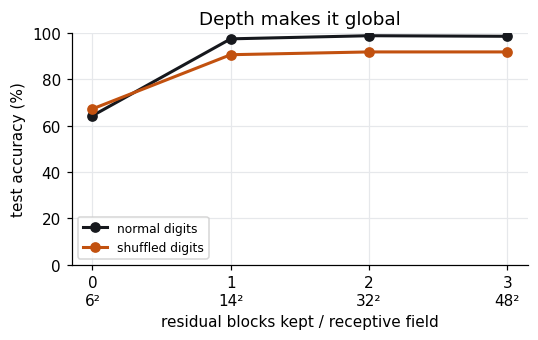

In [27]:
def run_depth(num_blocks, shuffle_pixels, seed=0):
    """Train a GAP CNN with only num_blocks residual blocks; return its test accuracy."""
    key = f"depth|{num_blocks}|{'perm' if shuffle_pixels else 'normal'}|{seed}"
    if key in RESULTS:
        return RESULTS[key]
    perm = PERM if shuffle_pixels else None
    model = make_model("cnn_gap", seed, num_blocks=num_blocks)
    train(model, X_train, y_train, steps(3750), perm=perm, seed=seed)
    result = {"test": accuracy(model, X_test, y_test, perm), "params": count_weights(model)}
    save_result(key, result)
    print(key, result)
    return result


depth_normal, depth_shuffled, depth_weights = [], [], []
for num_blocks in range(3):
    normal = run_depth(num_blocks, False)
    depth_normal.append(normal["test"])
    depth_weights.append(normal["params"])
    depth_shuffled.append(run_depth(num_blocks, True)["test"])
depth_normal.append(main_runs["CNN, GAP head"][0]["clean"])     # 3 blocks: seed 0 of the main runs
depth_shuffled.append(shuffled_runs[0]["clean"])
depth_weights.append(main_runs["CNN, GAP head"][0]["params"])

print("blocks kept       ", [0, 1, 2, 3])
print("normal digits %   ", [round(v, 1) for v in depth_normal])
print("shuffled digits % ", [round(v, 1) for v in depth_shuffled])
print("weights           ", depth_weights)

plt.figure(figsize=(5, 3.2))
plt.plot(range(4), depth_normal, "o-", color=INK, label="normal digits")
plt.plot(range(4), depth_shuffled, "o-", color=ORANGE, label="shuffled digits")
plt.xticks(range(4), ["0\n6²", "1\n14²", "2\n32²", "3\n48²"])
plt.xlabel("residual blocks kept / receptive field")
plt.ylabel("test accuracy (%)")
plt.ylim(0, 100)
plt.title("Depth makes it global")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Only the invariances you build in

The CNN builds in shift, not scale. Test digits are rescaled about the centre; the plain MLP and the CNN are the shift-test models (3 seeds), and a third model is the CNN trained with random rescaling between 0.8× and 1.2× (2 seeds). What to notice: the CNN drops off away from 1.0× too, and scale augmentation, not the architecture, fixes it.


main|cnn_gap|scale|None|0 test 99.0
main|cnn_gap|scale|None|1 test 98.9
plain MLP         [36.6, 55.9, 81.2, 93.9, 96.3, 94.5, 86.5, 74.0, 59.9]
CNN               [79.9, 94.3, 97.5, 98.3, 98.7, 98.4, 97.6, 94.8, 90.1]
CNN + scale aug.  [95.3, 98.0, 98.6, 98.9, 99.0, 98.9, 98.8, 98.4, 97.8]


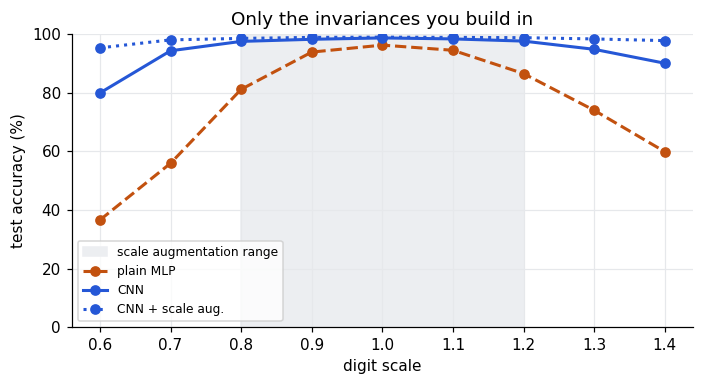

In [28]:
scale_aug_runs = [run_main("cnn_gap", "scale", seed=s) for s in seeds(2)]
scale_curve = {"plain MLP": mean_of(main_runs["plain MLP"], "scale"),
               "CNN": mean_of(main_runs["CNN, GAP head"], "scale"),
               "CNN + scale aug.": mean_of(scale_aug_runs, "scale")}
for name, values in scale_curve.items():
    print(f"{name:17s}", np.round(values, 1).tolist())

styles = {"plain MLP": (ORANGE, "--"), "CNN": (BLUE, "-"), "CNN + scale aug.": (BLUE, ":")}
plt.figure(figsize=(6.5, 3.6))
plt.axvspan(0.8, 1.2, color="#ECEEF1", zorder=0, label="scale augmentation range")
for name, (color, style) in styles.items():
    plt.plot(SCALES, scale_curve[name], color=color, ls=style, marker="o", label=name)
plt.ylim(0, 100)
plt.xlabel("digit scale")
plt.ylabel("test accuracy (%)")
plt.title("Only the invariances you build in")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Almost invariant

The share of test digits whose predicted class changes after a 1 px shift, averaged over the four directions and 3 seeds. Max pooling and zero padding at the borders make the CNN only *almost* shift-invariant. Slide: plain MLP 6.3%, MLP + augmentation 1.0%, CNN with dense head 1.2%, CNN with GAP head 0.7%.

plain MLP            6.1%
MLP + augmentation   1.0%
CNN, dense head      1.2%
CNN, GAP head        0.6%


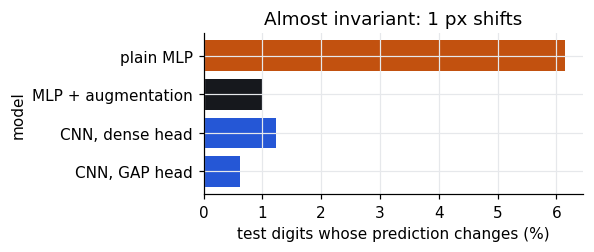

In [29]:
flip_rate = {name: np.mean([np.mean(run["flip1"]) for run in runs]) for name, runs in main_runs.items()}
for name, rate in flip_rate.items():
    print(f"{name:20s} {rate:.1f}%")

plt.figure(figsize=(5.5, 2.4))
plt.barh(list(flip_rate)[::-1], list(flip_rate.values())[::-1], color=[BLUE, BLUE, INK, ORANGE])
plt.xlabel("test digits whose prediction changes (%)")
plt.ylabel("model")
plt.title("Almost invariant: 1 px shifts")
plt.tight_layout()
plt.show()

### Borders matter too (optional, `RUN_PADDING_CHECK = True`)

The slide's *Borders matter too* card comes from an earlier round with a plain CNN (conv → pool → conv → …, no residual blocks): **unpadded**, 87.7% at 3 px and 52.7% at 6 px (one seed, lr 1e-3); **padded**, 96.3% and 89.5% (3 seeds). Without padding, pixels near the border reach fewer filter positions, so a shift changes what the network sees. This cell retrains those four models, so it is off by default.

In [30]:
class PlainCNN(nn.Module):
    """Padded plain CNN: conv5x5(16) -> pool -> conv5x5(32) -> pool -> conv3x3(64) -> GAP -> Linear."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 5, padding=2)
        self.conv2 = nn.Conv2d(16, 32, 5, padding=2)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.out = nn.Linear(64, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)     # 28 -> 14
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)     # 14 -> 7
        x = F.relu(self.conv3(x))
        return self.out(x.mean((2, 3)))


class UnpaddedCNN(nn.Module):
    """Unpadded plain CNN: conv5x5(32) -> pool -> conv5x5(64) -> GAP -> Linear."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 5)
        self.conv2 = nn.Conv2d(32, 64, 5)
        self.out = nn.Linear(64, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)     # 24 -> 12
        x = F.relu(self.conv2(x))                      # 8 x 8
        return self.out(x.mean((2, 3)))


def run_padding(name, model_class, lr, seed):
    """Train one plain CNN and return its accuracy on test digits shifted 0..6 px."""
    key = f"padding|{name}|{seed}"
    if key in RESULTS:
        return RESULTS[key]
    torch.manual_seed(seed)
    model = model_class().to(device)
    train(model, X_train, y_train, steps(3750), lr=lr, seed=seed)
    result = [accuracy(model, shift(X_test, d), y_test) for d in range(7)]
    save_result(key, result)
    return result


if RUN_PADDING_CHECK:
    unpadded = run_padding("unpadded", UnpaddedCNN, 1e-3, 0)
    padded = np.mean([run_padding("padded", PlainCNN, 2e-3, s) for s in seeds(3)], axis=0)
    print(f"unpadded: {unpadded[3]:.1f}% at 3 px, {unpadded[6]:.1f}% at 6 px")
    print(f"padded:   {padded[3]:.1f}% at 3 px, {padded[6]:.1f}% at 6 px")

---
## Two levers compared · Weaker bias, more data

*Two levers compared* collects numbers from the runs above: how exact each lever is, how many batches it needs, its cost in weights, and what happens when its assumption is wrong. *Weaker bias, more data* sets this lecture's 220 vs 1,323 batches beside published CIFAR-10 numbers that are not computed here: an MLP reaches about 75% from scratch and 95% only after ImageNet-21k pretraining (Bachmann et al., NeurIPS 2023); ResNet-110 reaches 93.6% (He et al., CVPR 2016).

In [31]:
aug_curve, gap_curve = shift_curve["MLP + augmentation"], shift_curve["CNN, GAP head"]
weights_mlp = count_weights(make_model("mlp", 0))
weights_cnn = count_weights(make_model("cnn_gap", 0))
print(f"How exact   | MLP + aug: {aug_curve[3]:.0f}% at 3 px, {aug_curve[6]:.0f}% at 6 px"
      f" | CNN: {gap_curve[3]:.0f}% at 3 px, {gap_curve[6]:.0f}% at 6 px")
print(f"Batches     | MLP + aug: 80% at {to80_aug}, 95% at {to95_aug} | CNN: 80% at {to80_cnn}, 95% at {to95_cnn}")
print(f"Cost        | {weights_mlp / weights_cnn:.0f}x fewer weights ({weights_cnn / 1000:.0f}k vs {weights_mlp / 1000:.0f}k)")
print(f"When wrong  | shuffled pixels: {mean_of(normal_runs, 'clean'):.1f}% -> {np.mean(shuffled_test):.1f}%")

How exact   | MLP + aug: 97% at 3 px, 74% at 6 px | CNN: 99% at 3 px, 98% at 6 px
Batches     | MLP + aug: 80% at 60, 95% at 1260 | CNN: 80% at 120, 95% at 252
Cost        | 8x fewer weights (57k vs 468k)
When wrong  | shuffled pixels: 98.7% -> 91.8%
